# **Sales Prediction Using Multi Layer Perceptron**

Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix, accuracy_score

Data Loading

In [2]:
df = pd.read_csv('/content/customer_dataset.csv')
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


Data Cleaning

In [3]:
df.isnull().sum()

,0
Age,0
EstimatedSalary,0
Purchased,0


Train-Test Spliting

In [4]:
x = df.iloc[:, : -1]
y = df.iloc[:, -1]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [5]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

Model Apply

In [6]:
mlp = MLPClassifier(
    hidden_layer_sizes=(8, 8),
    activation = "relu",
    solver = "adam",
    max_iter=400,
    random_state=42
)
mlp.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(8, 8), max_iter=400, random_state=42)

Loss Curve

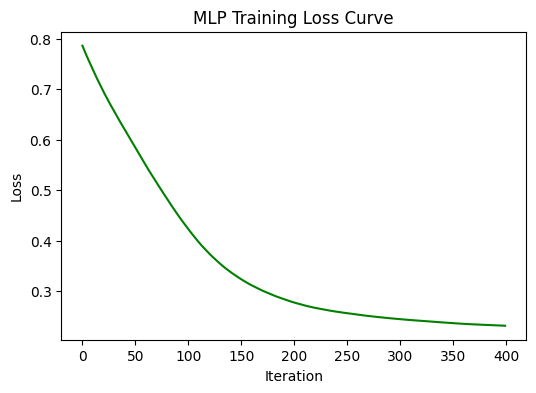

In [9]:
plt.figure(figsize = (6, 4))
plt.plot(mlp.loss_curve_, color = 'green')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Training Loss Curve')
plt.savefig('loss_curve.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [7]:
y_pred = mlp.predict(x_test)
print("\nConfusion Metrix: \n",confusion_matrix(y_test, y_pred))
print("\nClassification Report: \n",classification_report(y_test, y_pred))
print("\nAccuracy: \n",accuracy_score(y_test, y_pred))


Confusion Metrix: 
 [[48  4]
 [ 1 27]]

Classification Report: 
               precision    recall  f1-score   support

           0       0.98      0.92      0.95        52
           1       0.87      0.96      0.92        28

    accuracy                           0.94        80
   macro avg       0.93      0.94      0.93        80
weighted avg       0.94      0.94      0.94        80


Accuracy: 
 0.9375


Decision Boundary

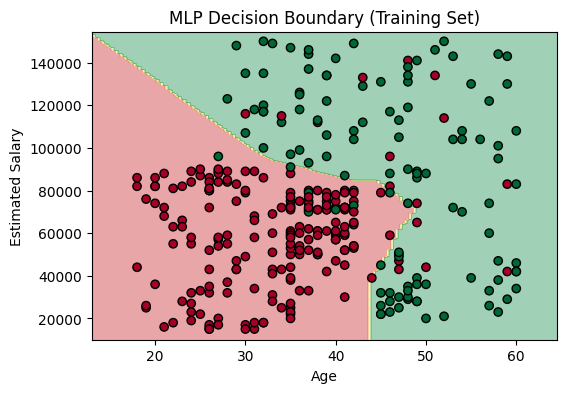

In [10]:
x_set = scaler.inverse_transform(x_train)
y_set = y_train.values

x1, x2 = np.meshgrid(np.arange(x_set[:, 0].min() - 5, x_set[:, 0].max() + 5, 0.5),
                     np.arange(x_set[:, 1].min() - 5000, x_set[:, 1].max() + 5000, 500))
grid = pd.DataFrame(np.c_[x1.ravel(), x2.ravel()], columns = ['Age', 'EstimatedSalary'])
zz = mlp.predict(scaler.transform(grid)).reshape(x1.shape)

plt.figure(figsize = (6, 4))
plt.contourf(x1, x2, zz, alpha = 0.4, cmap = 'RdYlGn')
plt.scatter(x_set[:, 0], x_set[:, 1], c = y_set, cmap = 'RdYlGn', edgecolors = 'k')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.title('MLP Decision Boundary (Training Set)')
plt.savefig('decision_boundary.png', dpi = 300, bbox_inches = 'tight')
plt.show()